# 4.2 Texte OCR + classifieurs entraînés : Dataset 2 (1er extrait, 30 000 images)

Mêmes vecteurs TF-IDF et même découpage qu'avec le cosinus, mais on entraîne une régression
logistique et un SVM (C choisi par validation croisée). `LinearSVC` est le SVM linéaire du cours, en
plus rapide sur les grands vecteurs du TF-IDF.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC
from statsmodels.stats.contingency_tables import mcnemar

from outils_4 import ARTEFACTS_30K, load_ocr_sample

warnings.filterwarnings("ignore", message="A worker stopped")  # avertissement joblib sans importance
train_df, test_df = load_ocr_sample()
y_train = train_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

vectoriseurs = {
    "mots, sans mots vides": TfidfVectorizer(ngram_range=(1, 2), strip_accents="unicode", sublinear_tf=True,
                                             stop_words=stopwords.words("english")),
    "caractères": TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True),
}
modeles = {
    "Régression logistique": (LogisticRegression(max_iter=2000), {"C": [0.01, 0.1, 1, 10, 100]}),
    "SVM": (LinearSVC(max_iter=5000, random_state=42), {"C": [0.001, 0.01, 0.1, 1, 10]}),
}

## 1. Les 4 combinaisons représentation × classifieur

In [2]:
lignes, predictions = [], {}
for nom_vect, vectoriseur in vectoriseurs.items():
    X_train = vectoriseur.fit_transform(train_df["text"])
    X_test = vectoriseur.transform(test_df["text"])
    for nom_modele, (modele, grille) in modeles.items():
        grid = GridSearchCV(modele, grille, cv=5, n_jobs=-1).fit(X_train, y_train)
        predictions[(nom_vect, nom_modele)] = grid.predict(X_test)
        lignes.append({"représentation": nom_vect, "classifieur": nom_modele, "meilleur C": grid.best_params_["C"],
                       "score validation croisée": grid.best_score_,
                       "accuracy test": accuracy_score(y_test, predictions[(nom_vect, nom_modele)])})

pd.DataFrame(lignes).round(3)

,représentation,classifieur,meilleur C,score validation croisée,accuracy test
0,"mots, sans mots vides",Régression logistique,0.1,0.757,0.794
1,"mots, sans mots vides",SVM,1.0,0.760,0.811
2,caractères,Régression logistique,100.0,0.792,0.861
3,caractères,SVM,1.0,0.796,0.869


## 2. Le meilleur : SVM sur TF-IDF caractères

                   precision    recall  f1-score   support

            email      1.000     0.950     0.974        60
             form      0.857     0.800     0.828        60
          invoice      0.823     0.850     0.836        60
     presentation      0.800     0.867     0.832        60
           resume      0.964     0.900     0.931        60
scientific_report      0.797     0.850     0.823        60

         accuracy                          0.869       360
        macro avg      0.873     0.869     0.871       360
     weighted avg      0.873     0.869     0.871       360



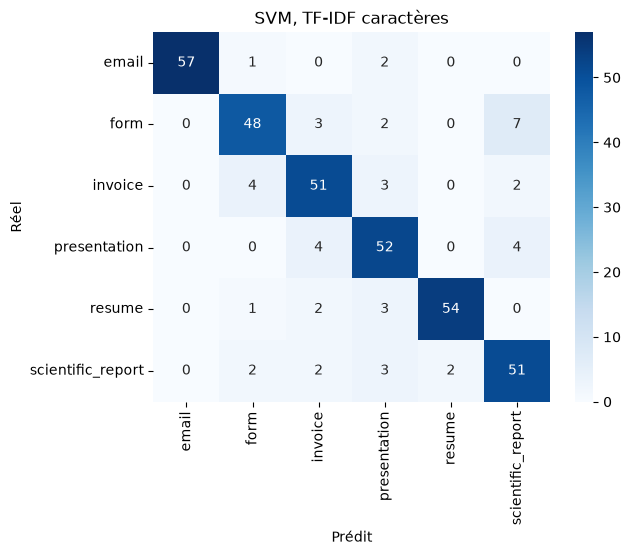

In [3]:
meilleur = predictions[("caractères", "SVM")]
print(classification_report(y_test, meilleur, digits=3))
matrice = pd.crosstab(y_test, meilleur, rownames=["Réel"], colnames=["Prédit"])
sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues")
plt.title("SVM, TF-IDF caractères")
plt.show()

## 3. Le bug de langue de l'OCR

Les mêmes 1 800 documents, relus avec l'ancien réglage (OCR en français) par `src/features/ocr.py`. Seul
le texte change. Le test de McNemar (vu en 4.5.1) dit si l'écart peut venir du hasard.

In [4]:
fra = pd.read_csv(f"{ARTEFACTS_30K}/ocr_echantillon_1800_fra.csv", keep_default_na=False)
eng = pd.concat([train_df, test_df])
print(f"Mots lus par document : {fra['text'].str.split().str.len().mean():.0f} en français, "
      f"{eng['text'].str.split().str.len().mean():.0f} en anglais")

vectoriseur = vectoriseurs["caractères"]
modele, grille = modeles["SVM"]
grid = GridSearchCV(modele, grille, cv=5, n_jobs=-1).fit(vectoriseur.fit_transform(fra.loc[train_df.index, "text"]), y_train)
juste_fra = grid.predict(vectoriseur.transform(fra.loc[test_df.index, "text"])) == y_test
juste_eng = meilleur == y_test
print(f"SVM, OCR en français : {juste_fra.mean():.1%} | OCR en anglais : {juste_eng.mean():.1%}")

corriges, casses = (~juste_fra & juste_eng).sum(), (juste_fra & ~juste_eng).sum()
tableau = [[(juste_fra & juste_eng).sum(), casses], [corriges, (~juste_fra & ~juste_eng).sum()]]
print(f"Documents corrigés : {corriges} | cassés : {casses} | McNemar p = {mcnemar(tableau, exact=True).pvalue:.2f}")

Mots lus par document : 123 en français, 135 en anglais


SVM, OCR en français : 83.9% | OCR en anglais : 86.9%
Documents corrigés : 21 | cassés : 10 | McNemar p = 0.07


L'OCR en anglais lit 10 % de mots en plus et le SVM gagne 3 points (11 documents sur 360), à la
limite du hasard (p = 0,07).